# How does a ReAct agent choose a truss?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cmudrc/design-research-workshop/blob/workshop-three-agent-demos/notebooks/planar_truss_react.ipynb)

A client wants a light truss. A second client has the same span, load, and member stock but wants the largest factor of safety. Predict whether the clients will get the same design. Then change the brief and see which piece of evidence changes PyBot’s next action.

Run the numbered sections on a CPU. Workshop PyBot uses local Python rules, and a structural solver evaluates the trusses.

## 1. Set up

Run this cell once in Colab. In a local Jupyter environment with the workshop installed, start with section 2.

In [ ]:
# @title Install the workshop package { display-mode: "form" }
%pip -q install "design-research-workshop @ git+https://github.com/cmudrc/design-research-workshop.git@workshop-three-agent-demos"

## 2. Inspect the starting geometry

The span is 10 m. A pin supports joint 0, a roller supports joint 1, and a 1,000 N load acts downward at joint 2. Joint 3 is available for an internal brace. The solver includes member self-weight. The four joint positions, member section, and material stay fixed across cases. Which joint pairs would you connect first?

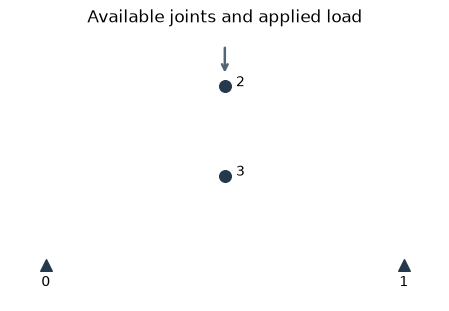

In [1]:
# @title Show the four-joint span and prepare the tools { display-mode: "form" }
import json
import math
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from design_research_workshop import workshop_client
from design_research_workshop.truss import TrussDesign, truss_agent

def plot_design(ax, state, title):
    joints = {joint.joint_id: joint for joint in state.joints}
    for member in state.members:
        left, right = joints[member.start_joint_id], joints[member.end_joint_id]
        ax.plot([left.x, right.x], [left.y, right.y], color="#9C2035", lw=3)
    for joint in joints.values():
        marker = "o" if joint.support_type == "free" else "^"
        ax.scatter(joint.x, joint.y, s=70, marker=marker, color="#24394B", zorder=3)
        offset = (8, 0) if joint.support_type == "free" else (0, -15)
        ax.annotate(str(joint.joint_id), (joint.x, joint.y), xytext=offset,
                    ha="left" if joint.support_type == "free" else "center",
                    textcoords="offset points")
    loaded_joint = joints[state.load_joint_id]
    ax.annotate("", (loaded_joint.x, loaded_joint.y + 0.3),
                (loaded_joint.x, loaded_joint.y + 1.15),
                arrowprops={"arrowstyle": "->", "color": "#526575", "lw": 1.8})
    ax.set(xlim=(-1, state.span + 1), ylim=(-1, state.max_height + 1.55),
           title=title, aspect="equal")
    ax.axis("off")

def run_case(brief, try_first=None):
    design = TrussDesign(center_joint=True)
    task = json.dumps({"brief": brief, "try_first": try_first})
    with workshop_client() as client, truss_agent(client, design) as agent:
        result = agent.run(task)
    if not result.success:
        raise RuntimeError(result.error)
    return design, result

def show_trace(result):
    rows = ["| Step | Tool | Observation |", "| ---: | --- | --- |"]
    for step, call in enumerate(result.tool_results, 1):
        obs = call.result
        if call.tool_name == "truss.inspect":
            detail = f"{len(obs['members'])} installed. {len(obs['legal_additions'])} joint pairs available."
        elif call.tool_name == "truss.compare_layouts":
            detail = f"{obs['evaluated']} layouts analyzed. {len(obs['feasible_layouts'])} pass the model’s feasibility check."
        else:
            detail = f"{obs['status']} Installed members: {len(obs['members'])}."
        rows.append(f"| {step} | `{call.tool_name}` | {detail} |")
    display(Markdown("\n".join(rows)))
    if "mass_kg" in result.final_output:
        print("Reported design:", result.final_output["members"])
    else:
        print("PyBot stopped:", result.final_output.get("message", result.final_output.get("status")))
        print("Installed members:", result.final_output.get("members", []))

def show_candidates(result):
    comparison = next(call.result for call in result.tool_results
                      if call.tool_name == "truss.compare_layouts")
    rows = ["| Installed joint pairs | Mass (kg) | Safety factor | Peak deflection (mm) |",
            "| --- | ---: | ---: | ---: |"]
    for layout in sorted(comparison["feasible_layouts"], key=lambda option: option["mass_kg"]):
        pairs = ", ".join(f"{a}–{b}" for a, b in layout["members"])
        if layout["members"] == result.final_output.get("members"):
            pairs = f"**{pairs} (selected)**"
        rows.append(f"| {pairs} | {layout['mass_kg']:.2f} | {layout['factor_of_safety']:.3f} | {layout['max_deflection_mm']:.4f} |")
    display(Markdown("\n".join(rows)))

seed = TrussDesign(center_joint=True)
fig, ax = plt.subplots(figsize=(6.5, 3), layout="constrained")
plot_design(ax, seed.state, "Available joints and applied load")
plt.show()

## 3. Case A — Find the lightest feasible truss

PyBot can inspect the geometry, ask the solver to compare layouts, and add one member per action. TrussMe checks the small set of layouts with enough members to be rigid. A layout qualifies when the structural solve succeeds and the smallest member factor of safety is at least 1.

Run the mass brief. The comparison tool returns the feasible layouts. PyBot breaks mass ties using the smaller peak deflection. Use the table to check its choice.

In [2]:
mass_case, mass_result = run_case("Use the lightest feasible truss.")
show_trace(mass_result)
show_candidates(mass_result)

| Step | Tool | Observation |
| ---: | --- | --- |
| 1 | `truss.inspect` | 0 installed. 6 joint pairs available. |
| 2 | `truss.compare_layouts` | 7 layouts analyzed. 6 pass the model’s feasibility check. |
| 3 | `truss.add_member` | Added member 0–1. Installed members: 1. |
| 4 | `truss.add_member` | Added member 0–3. Installed members: 2. |
| 5 | `truss.add_member` | Added member 1–2. Installed members: 3. |
| 6 | `truss.add_member` | Added member 1–3. Installed members: 4. |
| 7 | `truss.add_member` | Added member 2–3. Installed members: 5. |

Reported design: [[0, 1], [0, 3], [1, 2], [1, 3], [2, 3]]


| Installed joint pairs | Mass (kg) | Safety factor | Peak deflection (mm) |
| --- | ---: | ---: | ---: |
| 0–1, 0–2, 0–3, 1–3, 2–3 | 57.64 | 2.012 | 0.9423 |
| **0–1, 0–3, 1–2, 1–3, 2–3 (selected)** | 57.64 | 2.012 | 0.7835 |
| 0–1, 0–2, 0–3, 1–2, 2–3 | 60.41 | 1.966 | 0.2794 |
| 0–1, 0–2, 1–2, 1–3, 2–3 | 60.41 | 1.966 | 0.2542 |
| 0–1, 0–2, 0–3, 1–2, 1–3 | 66.20 | 2.135 | 0.2473 |
| 0–1, 0–2, 0–3, 1–2, 1–3, 2–3 | 70.89 | 2.315 | 0.2467 |

## 4. Case B — Change the objective and propose a first edit

The second client wants the largest factor of safety. An initial sketch calls for a member from joint 0 to joint 99. Predict what the model will learn about that edit. In the trace, find the first action after the rejection.

Try a different objective in the form, or replace the joint pair with a legal edit such as `[0, 2]`. Each run starts with a fresh span.

The cell also repeats the same brief with PyBot choosing every edit. Compare the tool-call counts and installed members to isolate the effect of the proposed first edit.

In [3]:
brief = "Maximize the factor of safety."  # @param ["Maximize the factor of safety.", "Minimize peak deflection.", "Design the lightest truss with a safety factor of at least 2.2.", "Minimize deflection with at most 60 kg."] {allow-input: true}
try_first = [0, 99]  # Use None to let PyBot choose every edit.
edited_case, edited_result = run_case(brief, try_first)
show_trace(edited_result)

control_case, control_result = run_case(brief)
same_members = sorted(control_case.inspect({})["members"]) == sorted(edited_case.inspect({})["members"])
print(f"Tool calls with the proposed first edit: {len(edited_result.tool_results)}")
print(f"Tool calls with PyBot choosing every edit: {len(control_result.tool_results)}")
print("The runs installed the same members." if same_members else "The first edit changed the installed layout.")

| Step | Tool | Observation |
| ---: | --- | --- |
| 1 | `truss.inspect` | 0 installed. 6 joint pairs available. |
| 2 | `truss.compare_layouts` | 7 layouts analyzed. 6 pass the model’s feasibility check. |
| 3 | `truss.add_member` | Rejected 0–99. That member is outside the legal moves. Installed members: 0. |
| 4 | `truss.add_member` | Added member 0–1. Installed members: 1. |
| 5 | `truss.add_member` | Added member 0–2. Installed members: 2. |
| 6 | `truss.add_member` | Added member 0–3. Installed members: 3. |
| 7 | `truss.add_member` | Added member 1–2. Installed members: 4. |
| 8 | `truss.add_member` | Added member 1–3. Installed members: 5. |
| 9 | `truss.add_member` | Added member 2–3. Installed members: 6. |

Reported design: [[0, 1], [0, 2], [0, 3], [1, 2], [1, 3], [2, 3]]
Tool calls with the proposed first edit: 9
Tool calls with PyBot choosing every edit: 8
The runs installed the same members.


## 5. Check the built designs

Re-run the solver on the members actually installed in each case. Compare those values with PyBot’s reported measurements. How much extra mass did the second client accept, and what did it buy?

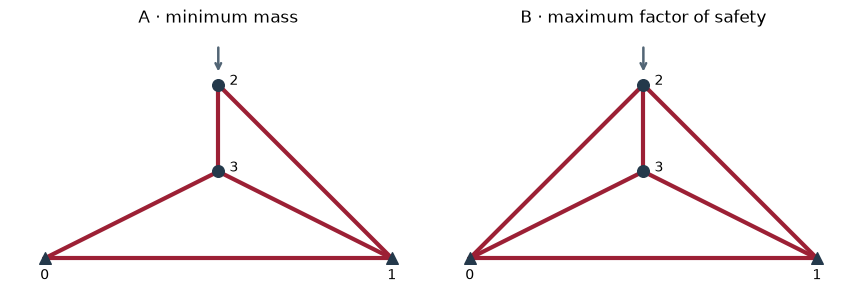

| Case | Members | Mass (kg) | Factor of safety | Peak deflection (mm) |
| --- | ---: | ---: | ---: | ---: |
| A · minimum mass | 5 | 57.64 | 2.012 | 0.7835 |
| B · maximum factor of safety | 6 | 70.89 | 2.315 | 0.2467 |

Case B minus Case A: +13.25 kg, +0.303 factor of safety, -0.537 mm peak deflection.


In [4]:
cases = [("A · minimum mass", mass_case, mass_result),
         ("B · " + edited_result.final_output.get("objective", "revised brief"), edited_case, edited_result)]
rows = ["| Case | Members | Mass (kg) | Factor of safety | Peak deflection (mm) |",
        "| --- | ---: | ---: | ---: | ---: |"]
checked_values = []
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3), layout="constrained")
for ax, (label, design, result) in zip(axes, cases, strict=True):
    report = result.final_output
    plot_design(ax, design.state, label)
    if "mass_kg" not in report:
        rows.append(f"| {label} | {len(design.state.members)} | — | — | — |")
        continue
    checked = design.grammar.evaluate(design.state)
    values = (checked.mass, checked.fos, 1_000 * checked.deflection)
    checked_values.append(values)
    assert checked.is_feasible
    assert all(math.isclose(value, report[key], rel_tol=1e-8)
               for value, key in zip(values, ("mass_kg", "factor_of_safety", "max_deflection_mm"), strict=True))
    rows.append(f"| {label} | {len(design.state.members)} | {values[0]:.2f} | {values[1]:.3f} | {values[2]:.4f} |")
plt.show()
display(Markdown("\n".join(rows)))
if len(checked_values) == 2:
    mass_change, fos_change, deflection_change = (b - a for a, b in zip(*checked_values, strict=True))
    print(f"Case B minus Case A: {mass_change:+z.2f} kg, {fos_change:+z.3f} factor of safety, "
          f"{deflection_change:+z.3f} mm peak deflection.")

## 6. Can the design meet both limits?

The client now asks for a truss weighing at most 60 kg with a factor of safety of at least 2.2. Use the candidate table in section 3 to predict how many layouts will qualify. Change either limit and rerun to test your prediction.

In [5]:
mass_limit_kg = 60.0  # @param {type:"number"}
minimum_fos = 2.2  # @param {type:"number"}
request = f"Minimize mass with at most {mass_limit_kg} kg and a safety factor of at least {minimum_fos}."
bounded_case, bounded_result = run_case(request)
show_trace(bounded_result)

comparison = next((step.result for step in bounded_result.tool_results
                   if step.tool_name == "truss.compare_layouts"), None)
if comparison is not None:
    layouts = comparison["feasible_layouts"]
    within_mass = [c for c in layouts if c["mass_kg"] <= mass_limit_kg]
    within_safety = [c for c in layouts if c["factor_of_safety"] >= minimum_fos]
    within_both = [c for c in within_mass if c["factor_of_safety"] >= minimum_fos]
    print(f"Layouts meeting the mass limit: {len(within_mass)}. Safety floor: {len(within_safety)}. Both: {len(within_both)}.")
    report = bounded_result.final_output
    assert bool(within_both) == ("mass_kg" in report)
    if within_both:
        built = bounded_case.grammar.evaluate(bounded_case.state)
        assert built.is_feasible and built.mass <= mass_limit_kg and built.fos >= minimum_fos
        print(f"Built configuration: {built.mass:.2f} kg and a safety factor of {built.fos:.3f}.")
    else:
        assert report["status"] == "no feasible completion" and not bounded_case.state.members
        if within_mass:
            print(f"Best safety factor within the mass limit: {report['best_fos_within_mass_limit']:.3f}.")
        if within_safety:
            print(f"Lightest layout meeting the safety floor: {report['least_mass_kg_meeting_fos_floor']:.2f} kg.")

| Step | Tool | Observation |
| ---: | --- | --- |
| 1 | `truss.inspect` | 0 installed. 6 joint pairs available. |
| 2 | `truss.compare_layouts` | 7 layouts analyzed. 6 pass the model’s feasibility check. |

PyBot stopped: no feasible completion
Installed members: []
Layouts meeting the mass limit: 2. Safety floor: 1. Both: 0.
Best safety factor within the mass limit: 2.012.
Lightest layout meeting the safety floor: 70.89 kg.


## Discuss

1. Which tool supplies evidence about a layout’s performance? Which tool confirms that a chosen member was installed?
2. Try the minimum-mass brief with a safety factor of at least 2.2. Does the first mass-optimal design still qualify? Which limit in section 6 would you negotiate, and by how much?
3. Give the minimum-mass agent a legal first edit of `[0, 2]`. Two layouts have the same minimum mass. Does that edit affect peak deflection? Which additional loads or joint positions would you want to try?

The comparisons use the same four joints under one load case with the packaged member properties. [Planar-truss grammar](https://cmudrc.github.io/design-research/tutorials/problems_truss_grammar.html)